# STEP 3 - Score the present value of top firms

Build the **present score** of the main firms of our Quantum Computing Sector: four indicators from PATSTAT, each with its refinements, combined into one ranking and tested for robustness.

In the PW our investment bank asks: **which firms of the sector hold the most valuable patents today?** In Step 3 of the deck we answer with a **present score**: one number per firm, which ranks the firms of our sector.

**Present** means: based on what has **already happened** to the patents (citations received, decisions of the examiners, countries where they are protected).


| Dimension | The question | In the Clarivate ranking | In this notebook (basics) | Lecture |
|---|---|---|---|---|
| **Volume** | How much does the firm invent? | a **gate**: only organizations with at least 100 inventions with a granted patent in 5 years are ranked | share of the sector's families; the gate is `MIN_FAMILIES` | size |
| **Success** | Do the examiners accept its inventions? | inventions with a granted patent ÷ inventions published as applications, last 5 years | granted ÷ filed EP applications | legal |
| **Globalization** | Are they protected in the main markets? | share of inventions with **quadrilateral** families: filed in China, Europe, Japan and the US | number of offices per family | economic |
| **Influence** | Do others build on them? | citations from other organizations, last 5 years, **self-citations excluded** | citations within 5 years ÷ mean of the same priority year | technological |

We rank the firms of **one sector**, so every indicator is relative to that sector.
We analyse one dimenion at a time, always in two parts: 

- **Basics**: the measure of the PW, the one that goes into the score;
- **Refinements**: better or richer versions of the same idea. We pick the ones that fit your sector and say why.

Then we combine the four basic indicators into **one ranking** and we check that the ranking is robust, and finally we show how to bring a refinement into the score.

Everything you choose here (window, firms, weights) is a **design decision** of your algorithm: write it down, you will justify it in the technical appendix of the deck.
- ragioanre su incumbent/entrant
- come scelgo le top firms? per ora con numero di famiglie di brevetti associate agli applicant, potremmo fare una lista a parte per gli entrants
- weights come li scelgo
- finestra temporale considerata
- consideriamo applications su scala globale e non su epo e basta 

## 1. Setup

In [61]:
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sqlalchemy import func, or_, and_

REPO = Path.cwd() if (Path.cwd() / "config").is_dir() else Path.cwd().parent
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

from stage00_config import load_config
cfg = load_config()

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,                 # applications: families, dates, grant
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,                # persons: harmonised names and sector
    TLS207_PERS_APPLN,            # person <-> application links (who is applicant)
    TLS209_APPLN_IPC,
    TLS211_PAT_PUBLN,             # publications
    TLS212_CITATION,              # citations between publications, with their origin
    TLS214_NPL_PUBLN,
    TLS215_CITN_CATEG,            # category of each citation (X, Y, A, I...)
    TLS224_APPLN_CPC,             # CPC classification: defines the sector
    TLS228_DOCDB_FAM_CITN,        # citations between DOCDB families
    TLS231_INPADOC_LEGAL_EVENT,   # legal events: refusals, fees paid in each state
    TLS230_APPLN_TECHN_FIELD
)

SECTOR_CPC_PREFIXES = cfg.cpc_prefixes
SECTOR_KEYWORDS = cfg.keywords 
SECTOR_KEYWORD_EXCLUSIONS = cfg.keyword_exclusions
IPR_TYPE = "PI" 
YEAR_MIN = 2000
YEAR_MAX = 2022

ENV = cfg.env
SECTOR_NAME = cfg.sector_name
patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV}")

OUT = Path("outputs/step3")        # the score is saved here for the Magic Quadrant
OUT.mkdir(exist_ok=True)

NAVY, ORANGE, BLUE, GREY, MID, LIGHT = "#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB", "#D9E1E8"
LINES = [NAVY, ORANGE, BLUE, "#7A9A3A", "#A23B72", MID]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
pd.set_option("display.max_colwidth", 45)

Sector: Quantum computing | env: PROD


## 2. The Quantum Computing Sector and its Applicants

- **Unit: the DOCDB family.** One invention is one family, whatever the number of applications it has (EP, divisional applications, US, CN...).
- **Time: the priority year** (`earliest_filing_year`, the date closest to the invention). We read 2000-2022: the whole period serves to follow the shares over time and to choose the window.
  
We extract the global dataset of these families along with their **applicants** (`applt_seq_nr > 0`). This gives us the raw ownership data needed for name harmonization.

In [62]:
def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))

def keyword_condition(terms, exclusions=()):
    """Any term appears in the title or abstract and no exclusion phrase does (case-insensitive).

    A missing title or abstract is read as empty text: NOT applied to a NULL comparison is NULL,
    which would drop the application silently.
    """
    title = func.lower(func.coalesce(TLS202_APPLN_TITLE.appln_title, ""))
    abstract = func.lower(func.coalesce(TLS203_APPLN_ABSTR.appln_abstract, ""))
    match = or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))
    if not exclusions:
        return match
    excluded = or_(*(col.like(f"%{x.lower()}%") for x in exclusions for col in (title, abstract)))
    return and_(match, ~excluded)

family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
by_cpc = (db.query(family_id)
          .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
          .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES)))

sector_ids = by_cpc
if SECTOR_KEYWORDS:
    by_kw = (db.query(family_id)
             .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
             .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
             .filter(keyword_condition(SECTOR_KEYWORDS, SECTOR_KEYWORD_EXCLUSIONS)))
    sector_ids = by_cpc.union(by_kw)

family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

q_sector = (
    db.query(families.c.unit_id, 
             families.c.year, 
             TLS206_PERSON.psn_id, 
             TLS206_PERSON.psn_name,
             TLS206_PERSON.psn_sector, 
             func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0) 
    .distinct()
)

raw_sector = patstat.df(q_sector)
print(f"Extracted {raw_sector['unit_id'].nunique():,} patent families with their respective applicants, priority years {YEAR_MIN}-{YEAR_MAX}")

Extracted 12,306 patent families with their respective applicants, priority years 2000-2022


### 2.1 The time window

Two indicators need **time**: patent offices worldwide take several years to examine and grant an application, and citations arrive over several years. Recent applications are not granted *yet*, and recent families are not cited *yet*: they would look weak only because they are young. 

The chart shows the share of global applications granted today, by priority year. Where the curve drops in recent years, the applications are not worse, just pending.

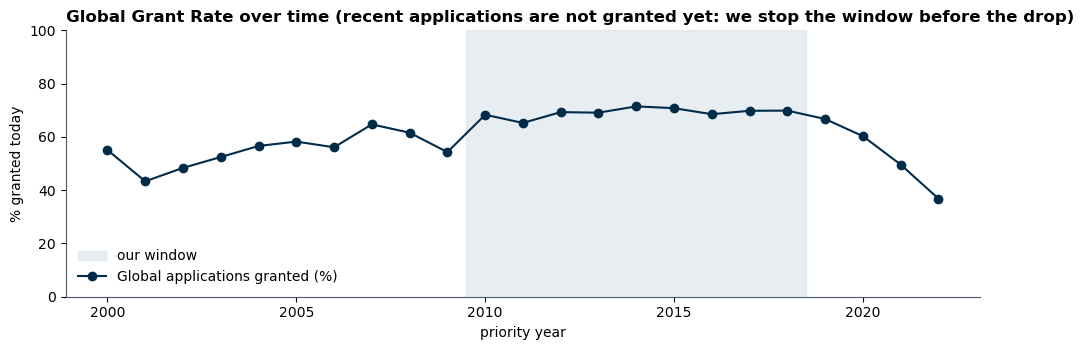

Window 2010-2018: 3,061 families, 7,772 GLOBAL applications


In [63]:
q_apps = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.granted
    )
    .filter(TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .filter(TLS201_APPLN.earliest_filing_year.between(YEAR_MIN, YEAR_MAX))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)

apps_all = patstat.df(q_apps).drop_duplicates("appln_id")

families_all = (
    apps_all.groupby("docdb_family_id")
          .agg(priority_year=("earliest_filing_year", "min"),
               first_publn_year=("earliest_publn_year", "min"))
          .reset_index()
)


WINDOW = (2010, 2018)       # the priority years we score: see the shaded area

grant_rate = apps_all.groupby("earliest_filing_year").granted.apply(lambda s: (s == "Y").mean())
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.6, label="our window")
ax.plot(grant_rate.index, grant_rate * 100, marker="o", color=NAVY, label="Global applications granted (%)")
ax.set_ylim(0, 100)
ax.set_xlabel("priority year")
ax.set_ylabel("% granted today")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Global Grant Rate over time (recent applications are not granted yet: we stop the window before the drop)")
plt.tight_layout()
plt.show()

apps = apps_all[apps_all.earliest_filing_year.between(*WINDOW)].copy()
families = families_all[families_all.priority_year.between(*WINDOW)].copy()
FAMILIES = [int(f) for f in families.docdb_family_id]
print(f"Window {WINDOW[0]}-{WINDOW[1]}: {len(FAMILIES):,} families, {len(apps):,} GLOBAL applications")

## 3. The firms: who owns which family?

The owners are the **applicants** (`applt_seq_nr > 0` in `TLS207`). A family filed by two firms together counts for **both** of them (*full counting*). We read the owners of the whole period, 2000-2022.

PATSTAT's default `psn_name` merges some spelling variants, but it does **not group different legal entities or subsidiaries of the same multinational together**. To solve this, we apply our harmonisation pipeline (`prepare_applicants` from `stage02_clean.py`), which strips legal forms and consolidates the global players specific to the Quantum Computing sector.

In [64]:
!pip install rapidfuzz cleanco


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [65]:
from stage02_clean import prepare_applicants 
from rapidfuzz import fuzz
import unicodedata
import re
from cleanco import basename

clean_owners = prepare_applicants(raw_sector, use_aliases=True, link=True)
clean_owners = clean_owners.rename(columns={
    "unit_id": "docdb_family_id",
    "applicant": "firm"
})

clean_owners = clean_owners[clean_owners["type"] == "firm"].copy() #if we want to consider only firms for our analysis 

print("\nDistribution by type (firm, university, government...):")
print(clean_owners["type"].value_counts(dropna=False))

print("\nTOP 15 PLAYER (after harmonisation) ---")
top_players = clean_owners.groupby("firm").docdb_family_id.nunique().sort_values(ascending=False).head(15)
print(top_players)


Distribution by type (firm, university, government...):
type
firm    9206
Name: count, dtype: int64

TOP 15 PLAYER (after harmonisation) ---
firm
IBM               599
ORIGIN QUANTUM    560
MICROSOFT         213
QUANTUMCTEK       201
D-WAVE SYSTEMS    199
GOOGLE            181
TOSHIBA           180
BAIDU             179
INTEL             154
NEC               133
NTT               129
IONQ              122
STATE GRID        119
FUJITSU           118
HUAWEI            110
Name: docdb_family_id, dtype: int64


### 3.1 Which firms do we score?

We score the top firms with the most families in our selected time window. This relies on two design choices:

- `N_FIRMS`: how many top firms to retain for the analysis (e.g., for the Magic Quadrant).
- `MIN_FAMILIES`: a minimum portfolio size threshold. With too few families, a single patent's grant or citation drastically swings the average, turning the indicator into noise.

In [66]:
N_FIRMS = 10
MIN_FAMILIES = 10

fam_firm = clean_owners[clean_owners.docdb_family_id.isin(FAMILIES)].copy()

n_families = fam_firm.groupby("firm").docdb_family_id.nunique().sort_values(ascending=False)
TOP = list(n_families[n_families >= MIN_FAMILIES].head(N_FIRMS).index)
SHORT = {f: (f.title()[:28] if len(f) > 5 else f) for f in TOP}     # short names for the charts

print(f"We score {len(TOP)} firms (Top {N_FIRMS} with at least {MIN_FAMILIES} families)")
n_families.loc[TOP].rename("families").to_frame()

We score 10 firms (Top 10 with at least 10 families)


,families
firm,
IBM,150
INTEL,88
GOOGLE,86
TOSHIBA,81
MICROSOFT,76
D-WAVE SYSTEMS,71
QUANTUMCTEK,64
STATE GRID,50
RIGETTI,49


In [67]:
def firm_bars(values, title, xlabel, fmt="{:.2f}", ref=None, ref_label=None, color=NAVY):
    """One horizontal bar per scored firm, in the order of TOP (largest portfolio on top)."""
    v = values.reindex(TOP)[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(v) + 1.2))
    ax.barh([SHORT[f] for f in v.index], v.values, color=color)
    for y, x in enumerate(v.values):
        if pd.notna(x):
            ax.text(x, y, (" " + fmt.format(x)) if x >= 0 else (fmt.format(x) + " "), va="center",
                    ha="left" if x >= 0 else "right", fontsize=9, color=GREY)
    if ref is not None:
        ax.axvline(ref, color=ORANGE, ls="--", lw=1.2)
        ax.text(ref, len(v) - 0.45, f" {ref_label}", color=ORANGE, fontsize=9, va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def per_firm(column, how="mean"):
    """Aggregate a column of `families` over the families of each scored firm."""
    table = fam_firm.merge(families[["docdb_family_id", column]], on="docdb_family_id")
    return table.groupby("firm")[column].agg(how).reindex(TOP).rename(column)

## 4. Volume: weight in the sector

### 4.1 Basics: share of the sector's families

$$\text{Volume}_f=\frac{\text{families of firm } f}{\text{all families of the sector in the window}}$$

The denominator is **all** the families of the window, including those of individuals, universities and small firms: volume is a share of the whole sector.

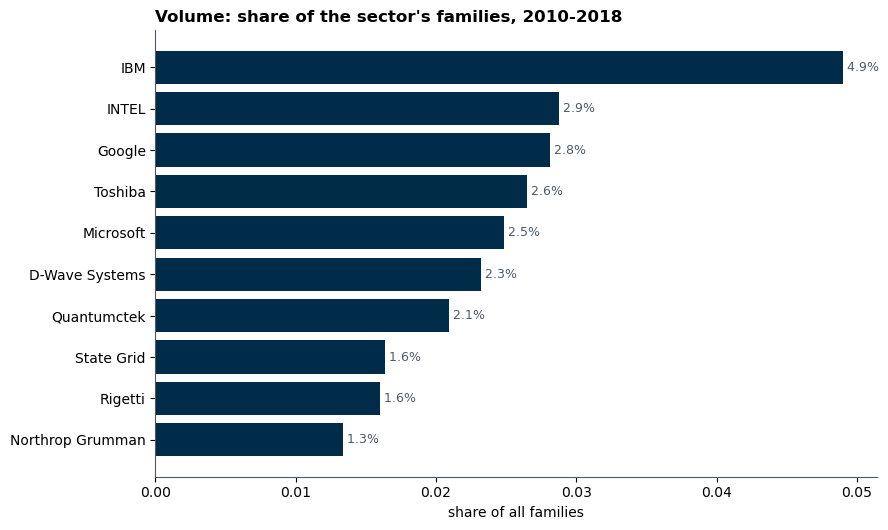

In [68]:
volume = (n_families / len(FAMILIES)).reindex(TOP).rename("volume")
firm_bars(volume, f"Volume: share of the sector's families, {WINDOW[0]}-{WINDOW[1]}", "share of all families", fmt="{:.1%}")

**Thinking about..** Volume measures size, not quality: a firm can file many cheap, narrow patents. We complement this metric with additional indicators (influence, success, globalization...) to capture the true technological impact of each portfolio.

### 4.2 Refinement: shares over time, who gains and who loses?

A single average number for the whole period hides the dynamics. The same share, **year by year**, shows changes of power in the sector.

$$\text{Share}_{f,t}=\frac{\text{families of firm } f \text{ with priority year } t}{\text{all families of the sector with priority year } t}$$

We plot it over the whole period, smoothed with a 3-year moving average (one year is often a handful of families). The last two years are incomplete because applications are published 18 months after filing; a share suffers less than a count, but read them with care.

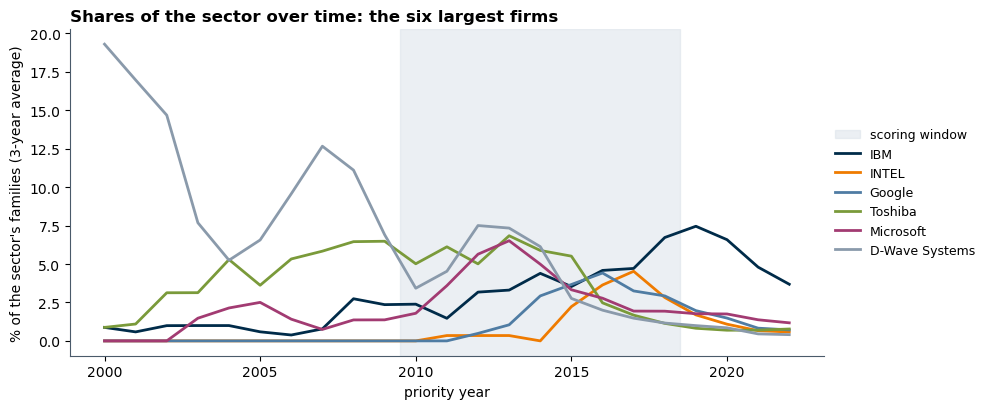

In [69]:
yearly = (clean_owners.merge(families_all[["docdb_family_id", "priority_year"]], on="docdb_family_id")
                     .groupby(["priority_year", "firm"]).docdb_family_id.nunique()
                     .unstack(fill_value=0))
total = families_all.groupby("priority_year").docdb_family_id.nunique()
share = yearly.reindex(columns=TOP, fill_value=0).div(total, axis=0)
smooth = share.rolling(3, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.5, label="scoring window")
for k, f in enumerate(TOP[:6]):
    ax.plot(smooth.index, smooth[f] * 100, color=LINES[k], lw=2, label=SHORT[f])
ax.set_xlabel("priority year")
ax.set_ylabel("% of the sector's families (3-year average)")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.set_title("Shares of the sector over time: the six largest firms")
plt.tight_layout()
plt.show()

To turn the dynamics into a number, the **change of share** inside the window: the average share in the second half (2015-2018) minus the average share in the first half (2010-2014), in percentage points. Positive means the firm is gaining weight.

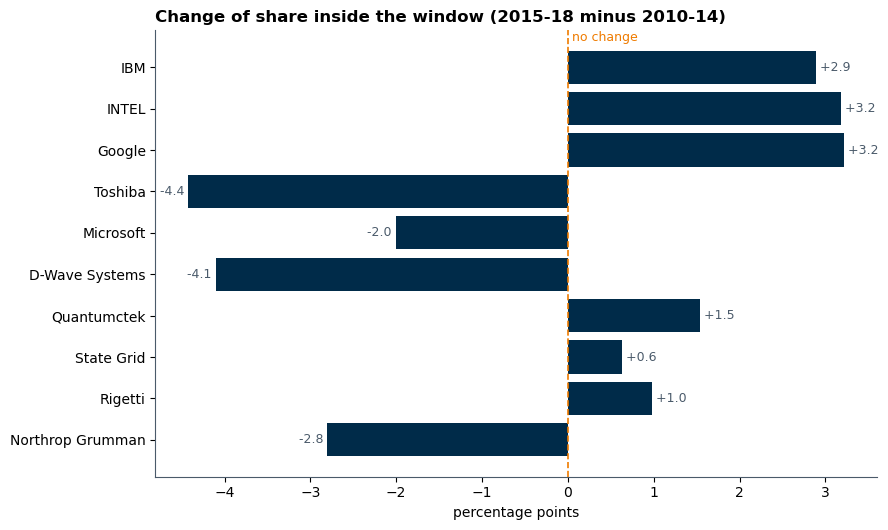

In [70]:
MID_YEAR = WINDOW[0] + (WINDOW[1] - WINDOW[0]) // 2
in_window = share.loc[WINDOW[0]:WINDOW[1]]
volume_change = ((in_window.loc[MID_YEAR + 1:].mean() - in_window.loc[:MID_YEAR].mean()) * 100).rename("volume_change")
firm_bars(volume_change, "Change of share inside the window (2015-18 minus 2010-14)", "percentage points",
          fmt="{:+.1f}", ref=0, ref_label="no change")

### 4.3 Refinement: Recent Momentum (Who is accelerating in the last 2 years of our window?)

A firm might have a large historical portfolio but low recent activity, or vice versa. To capture who is driving the current wave of Quantum Computing innovation, we measure **Recent Momentum**: the share of an enterprise's total portfolio filed in the most recent years of the window considered for the anlysis.

$$\text{Momentum}_{f}=\frac{\text{families of firm f}}{\text{total families of firm f in the window}}$$

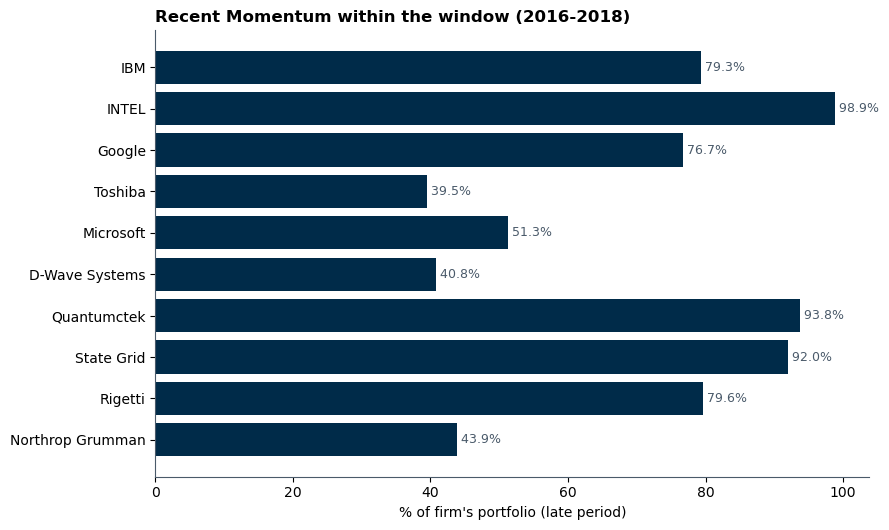

In [71]:
RECENT_WINDOW_START = 2016  # we consider as recent years, the last years of our considered window 

firm_with_years = clean_owners.merge(families_all[["docdb_family_id", "priority_year"]], on="docdb_family_id")
firm_in_window = firm_with_years[firm_with_years.docdb_family_id.isin(FAMILIES)]

recent_vol = firm_in_window[firm_in_window.priority_year >= RECENT_WINDOW_START].groupby("firm").docdb_family_id.nunique()
total_vol = firm_in_window.groupby("firm").docdb_family_id.nunique()

recent_momentum = ((recent_vol / total_vol) * 100).reindex(TOP).fillna(0).rename("recent_momentum") # % recents patents / 

firm_bars(
    recent_momentum, 
    f"Recent Momentum within the window ({RECENT_WINDOW_START}-{WINDOW[1]})", 
    "% of firm's portfolio (late period)", 
    fmt="{:.1f}%"
)

## 5. Influence: technological impact

### 5.1 Basics: forward citations within 5 years, compared with the same year

A family is influential if later inventions **build on it**, so we count its forward citations:

- **between families**: `TLS228_DOCDB_FAM_CITN` has one row per pair *citing family → cited family*, collecting the citations made by any publication of one family to any publication of the other;
- **within 5 years** of the first publication of the cited family, so that old and young families have the same time to be cited. The date of a citation is the first publication year of the **citing** family;
- we drop a family citing itself; citations from the same firm (self-citations) stay in, as in the OECD indicators.

First, the citations and their dates:

In [72]:
q = db.query(
    TLS228_DOCDB_FAM_CITN.docdb_family_id.label("citing_family"),
    TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("cited_family"),
).filter(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.in_(FAMILIES))

fcit = patstat.df(q)
fcit = fcit[fcit.citing_family != fcit.cited_family]

q_cit = (
    db.query(TLS201_APPLN.docdb_family_id, func.min(TLS201_APPLN.earliest_publn_year).label("year"))
    .filter(TLS201_APPLN.docdb_family_id.in_([int(f) for f in fcit.citing_family.unique()]))
    .filter(TLS201_APPLN.earliest_publn_year < 9999)
    .group_by(TLS201_APPLN.docdb_family_id)
)

fcit["citing_year"] = fcit.citing_family.map(patstat.df(q_cit).set_index("docdb_family_id").year)
fcit["cited_year"] = fcit.cited_family.map(families.set_index("docdb_family_id").first_publn_year)
fcit["lag"] = fcit.citing_year - fcit.cited_year         # years between the two first publications

print(f"{len(fcit):,} citing-cited pairs, from {fcit.citing_family.nunique():,} citing families")

53,013 citing-cited pairs, from 20,706 citing families


A raw count is unfair across years: older families had more citing patents around them and more time in the data. So we divide each family's count by the **mean of the families with the same priority year** $t$.

What about the **field**? Citation habits differ a lot between fields, so in general the comparison should be made within the same field and year. Here all families belong to our defined **Quantum Computing sector**: the technological scope is fixed by our sector boundary, and comparing within the year **is** like comparing within field and year.

$$\text{fwd}^{norm}_{i}=\frac{\text{fwd}_{i}}{\bar F_{t}}\qquad\text{with}\qquad \bar F_{t}=\frac{1}{N_{t}}\sum_{j\,\in\,t}\text{fwd}_{j}$$

- $\text{fwd}_i$: citations received by family $i$ within 5 years; $t$ is its priority year;
- $N_{t}$: the number of families of the sector with priority year $t$.

A value of **1** means "cited as much as the average family of the sector filed in the same year"; 2 means twice as much.

We write it as a function of the window `w`, because the refinements use other windows. A window is counted only if the data cover it: PATSTAT Spring 2026 has the citations up to about 2025 (`LAST_YEAR`), so a family first published in 2022 has no complete 5-year window, and its value is set to *missing* rather than to a count that is too low.

In [73]:
LAST_YEAR = 2025                      # last year of citations covered by the PATSTAT edition
COHORT = ["priority_year"]            # comparing based on priority year within our sector


def forward_citations(w):
    """Citations received within w years of the first publication; missing if the window is not complete."""
    counts = fcit[fcit.lag.between(0, w)].groupby("cited_family").citing_family.nunique()
    fwd = families.docdb_family_id.map(counts).fillna(0)
    complete = families.first_publn_year + w <= LAST_YEAR
    return fwd.where(complete)


def normalise_by_cohort(values):
    """Each family's value divided by the mean of the families with the same priority year."""
    mean_cohort = values.groupby([families[c] for c in COHORT]).transform("mean")
    return (values / mean_cohort).where(mean_cohort > 0, 0.0).where(values.notna())


families["fwd5"] = forward_citations(5)
families["fwd5_norm"] = normalise_by_cohort(families.fwd5)
families.groupby("priority_year").fwd5.mean().round(2).to_frame("mean fwd5 (the denominator)").T

priority_year,2010,2011,2012,2013,2014,2015,2016,2017,2018
mean fwd5 (the denominator),6.83,11.99,10.64,16.1,16.04,18.92,17.41,12.33,10.11


Read the means by year: they move from year to year, and they fall in the last years because younger families are cited less or the data stop. The normalisation removes this, because each family is compared only with the families of its own year. The influence of a firm is the **average** of its families:

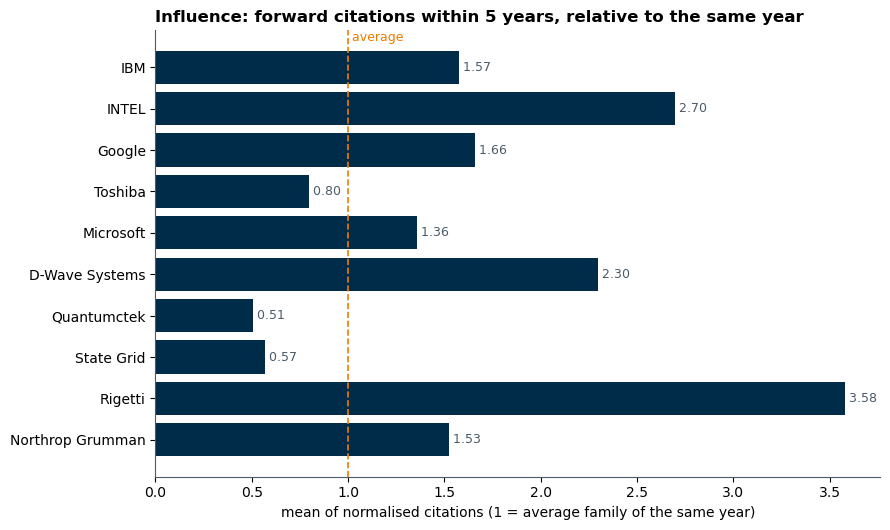

In [74]:
influence = per_firm("fwd5_norm").rename("influence")
firm_bars(influence, "Influence: forward citations within 5 years, relative to the same year",
          "mean of normalised citations (1 = average family of the same year)", ref=1, ref_label="average")

**Watch out.** An average is pulled up by one star family: a firm with 9 uncited families and one blockbuster can look influential. Refinement 5.4 looks at the top of the distribution instead.

### 5.2 Refinement: a shorter or a longer window (3 and 7 years)

A short window measures how fast a family is noticed; a long one is closer to its total impact, but the last priority years have no complete window yet, so it rests on the older families only. Does the window change the story?

In [75]:
for w in [3, 7]:
    families[f"fwd{w}_norm"] = normalise_by_cohort(forward_citations(w))

by_window = pd.concat([per_firm(f"fwd{w}_norm") for w in [3, 5, 7]], axis=1)
by_window.columns = ["3 years", "5 years", "7 years"]
print("Families with a complete window:",
      {w: f"{families[f'fwd{w}_norm'].notna().mean():.0%}" for w in [3, 5, 7]})
print("Rank correlation with the 5-year ranking:",
      by_window.corr(method="spearman")["5 years"].drop("5 years").round(2).to_dict())
by_window.rename(index=SHORT).round(2)

Families with a complete window: {3: '99%', 5: '98%', 7: '66%'}
Rank correlation with the 5-year ranking: {'3 years': 0.94, '7 years': 0.98}


,3 years,5 years,7 years
firm,,,
IBM,1.60,1.57,1.68
INTEL,3.23,2.70,2.48
Google,1.46,1.66,1.83
Toshiba,0.70,0.80,0.95
Microsoft,1.25,1.36,1.49
D-Wave Systems,2.18,2.30,2.40
Quantumctek,0.50,0.51,0.64
State Grid,0.50,0.57,1.04
Rigetti,3.18,3.58,4.58


If the order of the firms is the same in the three columns, the choice of the window does not matter much. A firm that climbs with the longer window has patents noticed late but used for long.

### 5.3 Refinement: who cites the firm, competitors or examiners?

A citation can be added by the **applicant** of the citing patent (origin `APP` in `TLS212`) or by the **examiner** during the search or examination (`SEA`, `ISR`, `SUP`, `EXA`...). The difference matters:

- an **applicant** citation means that a competitor *knew* the patent when it filed: a real knowledge flow, and visibility in the market;
- an **examiner** citation means that the patent is relevant prior art, which the citing applicant may never have read.

The origin is recorded at the level of **publications**, so we go from our global families to their publications (`TLS211`), then to the publications that cite them. We keep only citing **EP** publications: at the USPTO applicants must disclose all the prior art they know, so US applicant citations would mix different legal practices.

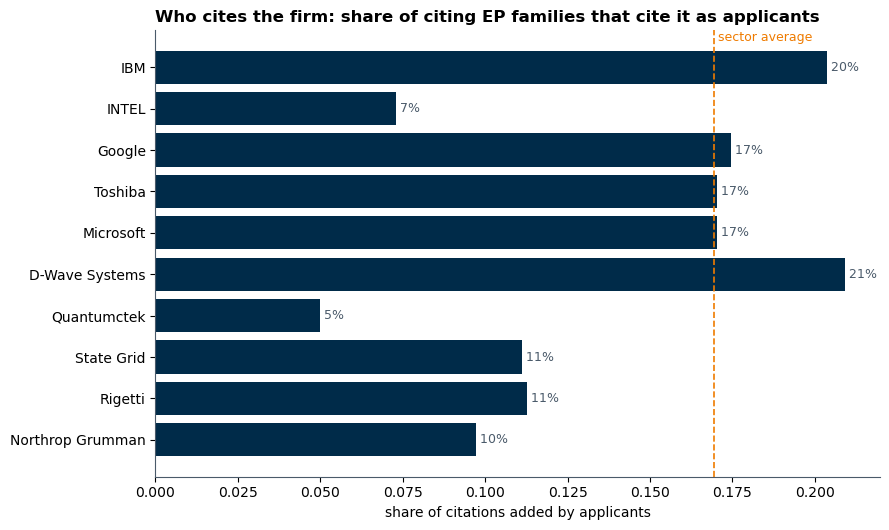

In [76]:
CITING_OFFICES = ["EP"]

# 1. All the publications of the families of the window (any office)
q = (db.query(TLS211_PAT_PUBLN.pat_publn_id, TLS201_APPLN.docdb_family_id.label("cited_family"))
     .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
     .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES)))
pubs = patstat.df(q)

# 2. The citations they receive, with their origin
q = (
    db.query(TLS212_CITATION.pat_publn_id.label("citing_publn"), TLS212_CITATION.citn_replenished,
             TLS212_CITATION.citn_id, TLS212_CITATION.citn_origin, TLS212_CITATION.cited_pat_publn_id)
    .filter(TLS212_CITATION.cited_pat_publn_id.in_([int(p) for p in pubs.pat_publn_id]))
)
cit = patstat.df(q)
cit["cited_family"] = cit.cited_pat_publn_id.map(pubs.set_index("pat_publn_id").cited_family)

# 3. The office and the family of each citing publication
q = (
    db.query(TLS211_PAT_PUBLN.pat_publn_id.label("citing_publn"), TLS211_PAT_PUBLN.publn_auth.label("citing_office"),
             TLS201_APPLN.docdb_family_id.label("citing_family"))
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS211_PAT_PUBLN.pat_publn_id.in_([int(p) for p in cit.citing_publn.unique()]))
)
cit = cit.merge(patstat.df(q), on="citing_publn")
cit = cit[cit.citing_family != cit.cited_family]
cit["who"] = np.where(cit.citn_origin.str.strip() == "APP", "applicant", "examiner or other")

ep_cit = (cit[cit.citing_office.isin(CITING_OFFICES)]
          .drop_duplicates(["citing_family", "cited_family", "who"])
          .merge(fam_firm, left_on="cited_family", right_on="docdb_family_id"))
applicant_share = (ep_cit.who == "applicant").groupby(ep_cit.firm).mean().reindex(TOP).rename("applicant_share")
firm_bars(applicant_share, "Who cites the firm: share of citing EP families that cite it as applicants",
          "share of citations added by applicants", fmt="{:.0%}",
          ref=(ep_cit.who == "applicant").mean(), ref_label="sector average")

A firm with a high applicant share is **watched by its competitors**: its patents are known reference points (read it with the number of citations)

### 5.4 Refinement: blocking patents, X and I citations at the top of the sector

Not all citations are equal. In a search report the examiner gives each cited document a **category** (`TLS215_CITN_CATEG`):

| Category | Meaning for the citing application |
|---|---|
| **X** | the cited document **alone** destroys the novelty or the inventive step of the claim |
| **I** | the cited document **alone** destroys the inventive step of the claim (EPO, since 2012) |
| Y | relevant only in combination with another document |
| A | general background |

A family often cited as **X or I** stood in the way of later applications: competitors had to narrow their claims or give up. It is a **blocking patent**, the strongest form of influence. `CITN_CATEG` can hold several letters (e.g. `XI`), so we look for an X or an I anywhere in it.

For each family we count the distinct families that cite it as X or I, and we call **blocking** the families in the **top 10% of their priority year**, with at least one such citation. As in 5.1, comparing inside the year is fair to young families, and the field is fixed by our global sector boundary.

Each family is then **blocking (1) or not (0)**. For a firm we compute two numbers from these 0/1 values:

$$\text{Blocking share}_f=\frac{\text{blocking families of } f}{\text{families of } f}\qquad\qquad \text{Share of the sector's blocking}_f=\frac{\text{blocking families of } f}{\text{all blocking families of the sector}}$$

The first is the average of the 0/1 values over the firm's families: the share of its portfolio that blocks others.

In [77]:
TOP_SHARE = 0.10              # top 10% of each priority year

q = (
    db.query(TLS215_CITN_CATEG.pat_publn_id.label("citing_publn"), TLS215_CITN_CATEG.citn_replenished,
             TLS215_CITN_CATEG.citn_id, TLS215_CITN_CATEG.citn_categ)
    .filter(TLS215_CITN_CATEG.pat_publn_id.in_([int(p) for p in cit.citing_publn.unique()]))
)
categ = patstat.df(q)
xi_keys = categ[categ.citn_categ.str.contains("X|I", regex=True)][["citing_publn", "citn_replenished", "citn_id"]]
xi = cit.merge(xi_keys.drop_duplicates(), on=["citing_publn", "citn_replenished", "citn_id"])

families["xi"] = families.docdb_family_id.map(xi.groupby("cited_family").citing_family.nunique()).fillna(0)
threshold = families.groupby(COHORT).xi.transform(lambda s: s.quantile(1 - TOP_SHARE))   # cut-off of each year
families["blocking"] = ((families.xi > threshold) & (families.xi > 0)).astype(int)

owners_of = fam_firm.groupby("docdb_family_id").firm.agg(", ".join)     # co-owned families: all owners
print(f"Blocking families: {families.blocking.sum():,} of {len(families):,}. The ten strongest:")
(families.assign(owners=families.docdb_family_id.map(owners_of).fillna("(not a company)"))
         .sort_values("xi", ascending=False)[["docdb_family_id", "priority_year", "xi", "owners"]].head(10))

Blocking families: 239 of 3,061. The ten strongest:


,docdb_family_id,priority_year,xi,owners
1292,54554938,2014,20.0,RIGETTI
2091,60935992,2017,11.0,GOOGLE
918,47992613,2011,9.0,LOS ALAMOS NATIONAL SECURITY
1722,58662742,2015,9.0,(not a company)
3419,67301223,2018,9.0,BIOVENTURES
2267,62075687,2016,8.0,HUAWEI
3848,68766205,2018,8.0,ATOM COMPUTING
1195,52997221,2015,8.0,HITACHI
1111,52007585,2013,8.0,"QUANTUM COMMUNICATION TECHNOLOGY, QUANTUM..."
2272,62091366,2015,8.0,RIGETTI


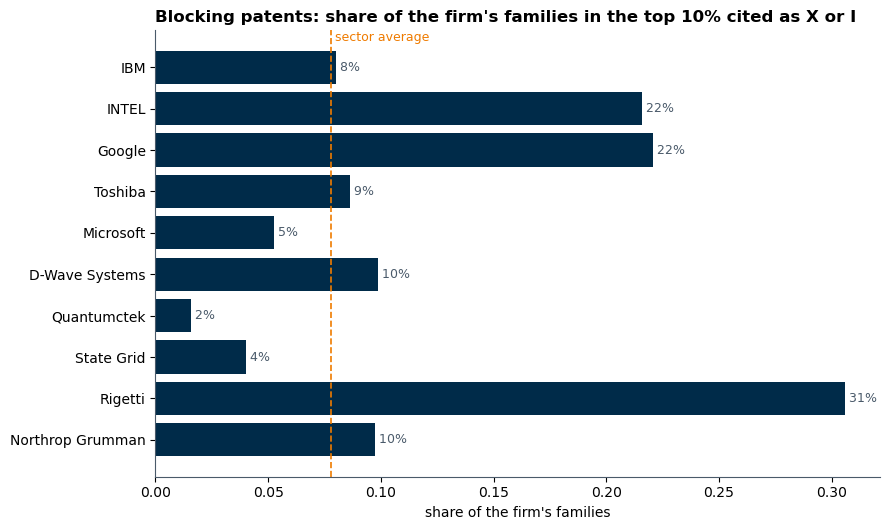

,blocking families,blocking_share,share_of_sector_blocking
firm,,,
IBM,12,0.08,0.05
INTEL,19,0.22,0.08
Google,19,0.22,0.08
Toshiba,7,0.09,0.03
Microsoft,4,0.05,0.02
D-Wave Systems,7,0.10,0.03
Quantumctek,1,0.02,0.00
State Grid,2,0.04,0.01
Rigetti,15,0.31,0.06


In [78]:
blocking_share = per_firm("blocking").rename("blocking_share")                 # mean of 0/1 = share of families
blocking_power = (per_firm("blocking", "sum") / families.blocking.sum()).rename("share_of_sector_blocking")

firm_bars(blocking_share, f"Blocking patents: share of the firm's families in the top {TOP_SHARE:.0%} cited as X or I",
          "share of the firm's families", fmt="{:.0%}", ref=families.blocking.mean(), ref_label="sector average")
pd.concat([per_firm("blocking", "sum").rename("blocking families"), blocking_share, blocking_power],
          axis=1).rename(index=SHORT).round(2)

`blocking_share` is the **quality** of the portfolio (how many of its families block others), `share_of_sector_blocking` is the **power** in the sector (how many of the sector's blocking patents the firm owns).

### 5.5 Refinement: backward citations and citations to science

While forward citations measure future impact, **backward citations** and **non-patent literature (NPL) citations** measure the foundations of the invention:

- **Backward citations:** The number of earlier patent documents cited by the invention (excluding NPL, self-citations included). A high count indicates that the patent underwent rigorous screening against an extensive prior art landscape, reflecting technological solidity.
- **Citations to science (NPL):** Links to scientific papers and non-patent literature (`cited_npl_publn_id > 0`). In fields like Quantum Computing, inventions tightly coupled with academic and scientific literature tend to be more radical and of higher technological quality.

As with forward citations, we normalise these metrics by priority year cohort to account for generational differences in citation intensity.

npl_type
a    33838
s     5652
w     1002
b      257
e        3
d        1
Name: count, dtype: int64


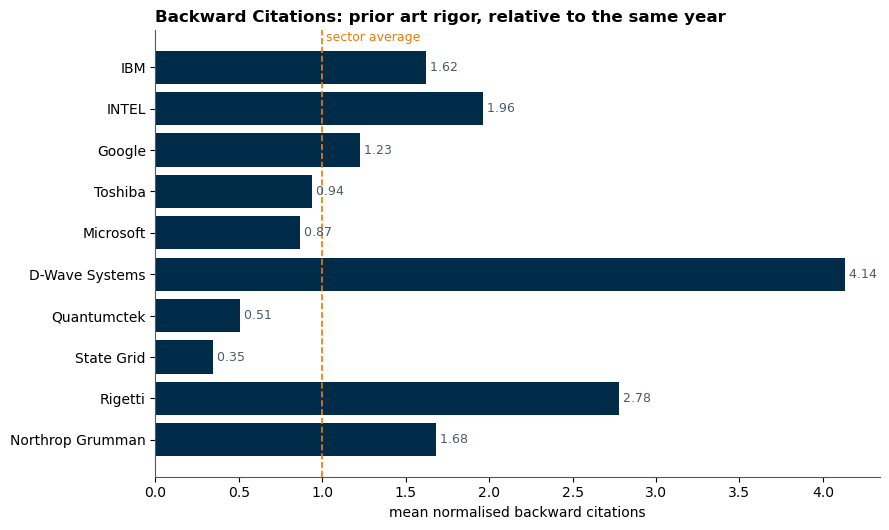

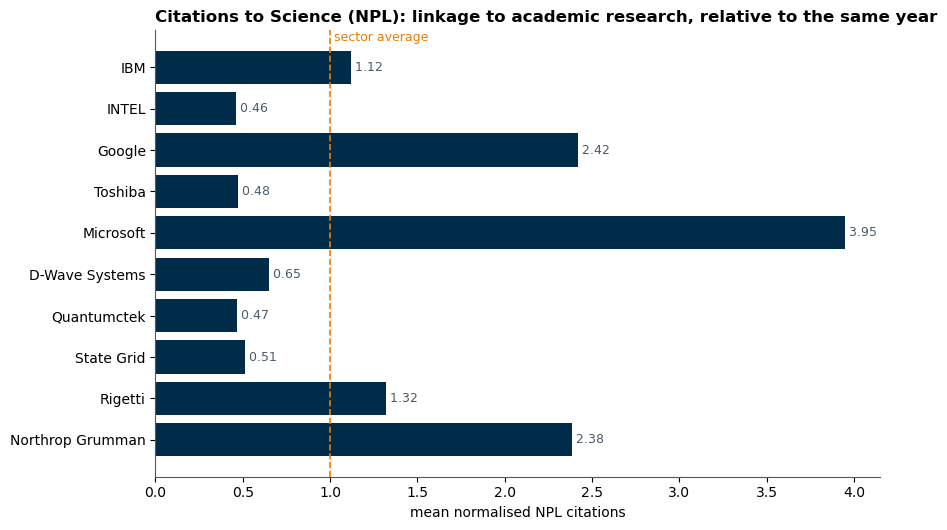

,backward_citations,science_citations
firm,,
IBM,1.62,1.12
INTEL,1.96,0.46
Google,1.23,2.42
Toshiba,0.94,0.48
Microsoft,0.87,3.95
D-Wave Systems,4.14,0.65
Quantumctek,0.51,0.47
State Grid,0.35,0.51
Rigetti,2.78,1.32


In [79]:
# Backward Patent Citations per family (excluding NPL)
q_back = (
    db.query(
        TLS201_APPLN.docdb_family_id.label("citing_family"),
        TLS212_CITATION.pat_publn_id,
        TLS212_CITATION.cited_pat_publn_id,
        TLS212_CITATION.cited_npl_publn_id
    )
    .join(TLS211_PAT_PUBLN, TLS211_PAT_PUBLN.pat_publn_id == TLS212_CITATION.pat_publn_id)
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
)
back_df = patstat.df(q_back)

back_df["cited_pat_publn_id"] = pd.to_numeric(back_df["cited_pat_publn_id"], errors="coerce").fillna(0)
back_df["cited_npl_publn_id"] = pd.to_numeric(back_df["cited_npl_publn_id"], errors="coerce").fillna(0)

back_pat = back_df[back_df.cited_pat_publn_id > 0].groupby("citing_family").cited_pat_publn_id.nunique()
families["back_citations"] = families.docdb_family_id.map(back_pat).fillna(0)

# Citations to science (NPL) per family 
q_npl = (
    db.query(TLS201_APPLN.docdb_family_id.label("citing_family"),
             TLS214_NPL_PUBLN.npl_publn_id, TLS214_NPL_PUBLN.npl_type)
    .select_from(TLS201_APPLN)
    .join(TLS211_PAT_PUBLN, TLS211_PAT_PUBLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS212_CITATION, TLS212_CITATION.pat_publn_id == TLS211_PAT_PUBLN.pat_publn_id)
    .join(TLS214_NPL_PUBLN, TLS214_NPL_PUBLN.npl_publn_id == TLS212_CITATION.cited_npl_publn_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS212_CITATION.cited_npl_publn_id != "0")  
    .distinct()
)
npl = patstat.df(q_npl)
npl = npl[~npl.npl_publn_id.astype(str).str.strip().isin(["", "0"])]
print(npl.npl_type.value_counts())          # check which type are the journal articles
# scientific = articles only ("s" in the tutorial); not all NPL is science
sci = npl[npl.npl_type == "s"]
families["sci_citations"] = families.docdb_family_id.map(sci.groupby("citing_family").npl_publn_id.nunique()).fillna(0)


families["back_norm"] = normalise_by_cohort(families.back_citations)
families["sci_norm"] = normalise_by_cohort(families.sci_citations)

back_firm = per_firm("back_norm").rename("backward_citations")
sci_firm = per_firm("sci_norm").rename("science_citations")

firm_bars(back_firm, "Backward Citations: prior art rigor, relative to the same year", 
          "mean normalised backward citations", ref=1, ref_label="sector average")

firm_bars(sci_firm, "Citations to Science (NPL): linkage to academic research, relative to the same year", 
          "mean normalised NPL citations", ref=1, ref_label="sector average")

pd.concat([back_firm, sci_firm], axis=1).rename(index=SHORT).round(2)

### 5.6 Refinement: Originality and Generality

To understand the structural nature of a firm's technology portfolio, we compute two classic indexes based on CPC/IPC technological classes (using the Herfindahl-Hirschman dispersion index $1 - \sum s_{ik}^2$):

- **Originality:** Measures how widely recombinant an invention is. A high originality score means the patent builds upon prior art drawn from many different, distant technological fields.
- **Generality:** Measures how widely a patent is applied later. A high generality score means the patent is cited by subsequent inventions spanning a broad range of diverse technological fields, acting much like a General-Purpose Technology (GPT).

Both metrics are aggregated at the firm level to evaluate the breadth of their R&D output.

Families with a value: {'originality': 0.65, 'generality': 0.64}


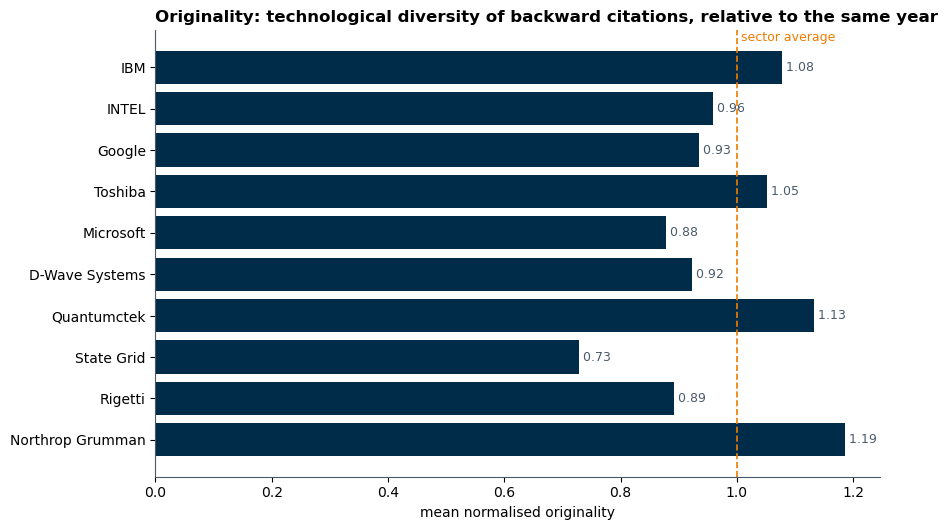

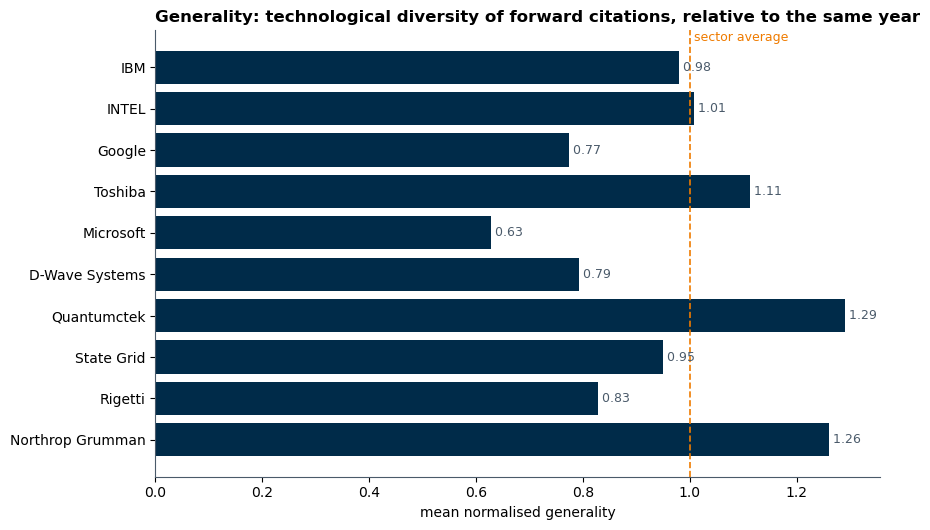

,originality,generality
firm,,
IBM,1.08,0.98
INTEL,0.96,1.01
Google,0.93,0.77
Toshiba,1.05,1.11
Microsoft,0.88,0.63
D-Wave Systems,0.92,0.79
Quantumctek,1.13,1.29
State Grid,0.73,0.95
Rigetti,0.89,0.83


In [80]:
def family_fields(family_ids):
    """WIPO field shares of each DOCDB family (weights summed over its applications)."""
    ids, out = [int(i) for i in family_ids], []
    for s in range(0, len(ids), 5000):
        q = (db.query(TLS201_APPLN.docdb_family_id, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                      func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w"))
             .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
             .filter(TLS201_APPLN.docdb_family_id.in_(ids[s:s + 5000]))
             .group_by(TLS201_APPLN.docdb_family_id, TLS230_APPLN_TECHN_FIELD.techn_field_nr))
        out.append(patstat.df(q))
    f = pd.concat(out)
    f["w"] = f.w.astype(float)
    f["w"] = f.w / f.groupby("docdb_family_id").w.transform("sum")
    return f


def dispersion(pairs, key, other, fields, min_n=5):
    """1 - sum of squared field shares over the `other` families linked to `key`.
    Hall-Jaffe correction n/(n-1); NaN below min_n links (the index is unstable)."""
    t = pairs.merge(fields.rename(columns={"docdb_family_id": other}), on=other)
    w = t.groupby([key, "techn_field_nr"]).w.sum().reset_index()
    w["s"] = w.w / w.groupby(key).w.transform("sum")
    d = 1 - (w.s ** 2).groupby(w[key]).sum()
    n = pairs.groupby(key)[other].nunique().reindex(d.index)
    return (d * n / (n - 1)).where(n >= min_n)

# 1. ORIGINALITY (Based on Backward Citations) Map cited publications -> families
cited_pubs = back_df.loc[back_df.cited_pat_publn_id > 0, "cited_pat_publn_id"].astype("int64").unique()
maps = []
for s in range(0, len(cited_pubs), 5000):
    q = (db.query(TLS211_PAT_PUBLN.pat_publn_id.label("cited_pat_publn_id"),
                  TLS201_APPLN.docdb_family_id.label("cited_family"))
         .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
         .filter(TLS211_PAT_PUBLN.pat_publn_id.in_([int(p) for p in cited_pubs[s:s + 5000]])))
    maps.append(patstat.df(q))
pub2fam = pd.concat(maps).drop_duplicates("cited_pat_publn_id")

b = back_df[back_df.cited_pat_publn_id > 0].copy()
b["cited_pat_publn_id"] = b.cited_pat_publn_id.astype("int64")
back_pairs = (b.merge(pub2fam, on="cited_pat_publn_id")[["citing_family", "cited_family"]]
                .drop_duplicates().query("citing_family != cited_family"))


# 2. GENERALITY (Based on Forward Citations) citing families within 5 years (same window as influence)
fwd_pairs = fcit[fcit.lag.between(0, 5)][["citing_family", "cited_family"]].drop_duplicates()

fields = family_fields(set(back_pairs.cited_family) | set(fwd_pairs.citing_family))

families["originality"] = families.docdb_family_id.map(dispersion(back_pairs, "citing_family", "cited_family", fields))
families["generality"] = families.docdb_family_id.map(dispersion(fwd_pairs, "cited_family", "citing_family", fields))
families["orig_norm"] = normalise_by_cohort(families.originality)
families["gen_norm"] = normalise_by_cohort(families.generality)
print("Families with a value:", families[["originality", "generality"]].notna().mean().round(2).to_dict())

orig_firm = per_firm("orig_norm").rename("originality")
gen_firm = per_firm("gen_norm").rename("generality")

firm_bars(
    orig_firm, 
    "Originality: technological diversity of backward citations, relative to the same year", 
    "mean normalised originality", 
    ref=1, 
    ref_label="sector average"
)

firm_bars(
    gen_firm, 
    "Generality: technological diversity of forward citations, relative to the same year", 
    "mean normalised generality", 
    ref=1, 
    ref_label="sector average"
)

orig_firm.rename(index=SHORT).round(2)
gen_firm.rename(index=SHORT).round(2)
pd.concat([orig_firm, gen_firm], axis=1).rename(index=SHORT).round(2)


In [81]:
n_used = (fam_firm.merge(families[["docdb_family_id", "orig_norm", "gen_norm"]], on="docdb_family_id")
                  .groupby("firm")[["orig_norm", "gen_norm"]].count()
                  .reindex(TOP)
                  .rename(columns={"orig_norm": "n families with originality",
                                   "gen_norm": "n families with generality"}))
n_used["families in the window"] = n_families.reindex(TOP)

n_used.rename(index=SHORT)

,n families with originality,n families with generality,families in the window
firm,,,
IBM,145,135,150
INTEL,79,87,88
Google,78,83,86
Toshiba,68,59,81
Microsoft,56,71,76
D-Wave Systems,65,70,71
Quantumctek,37,27,64
State Grid,23,20,50
Rigetti,46,46,49


## 6. Success: quality as judged by the examiners

Success asks: **when the firm applies for a patent, do the examiners accept it?** A granted patent has passed an examination of novelty and inventive step, so a high grant rate signals inventions of good quality and well-drafted applications. 

### 6.1 Basics: share of global applications granted

Because many firms in our global dataset do not restrict their filings to the EPO, measuring success exclusively through European applications would create a bias. Instead, we compute the success rate across all national and regional patent offices where the firm files:

$$\text{Success}_f=\frac{\text{granted global applications of firm } f}{\text{global applications of firm } f}$$

`granted` is `Y` when PATSTAT has an indication of a grant, `N` otherwise. `N` therefore mixes refused, withdrawn and still pending applications; with the window ending in 2018 most applications have been decided. 
To focus purely on active substantive examinations, we exclude:
- **`WO`**: a PCT application is a request, not protection in a country;
- **`T`** (`appln_kind` in `TLS201`): translations of granted EP patents recorded as national applications in certain countries (Spain, Portugal, Poland, Denmark, Austria, etc.), which are always "granted" by default and counting it would inflate both success and globalization.

In [82]:
q = (
    db.query(
        TLS201_APPLN.appln_id, 
        TLS201_APPLN.docdb_family_id, 
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind, 
        TLS201_APPLN.granted
    )
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)
members = patstat.df(q).drop_duplicates("appln_id")

# national applications: exclude PCT requests (WO) and translations of EP patents (kind T)
national = members[(members.appln_auth != "WO") & (members.appln_kind != "T")]

office_rate = national.groupby("appln_auth").agg(
    applications=("appln_id", "size"),
    granted=("granted", lambda s: (s == "Y").mean())
)
display(office_rate[office_rate.applications >= 20].sort_values("granted", ascending=False).round(2).T)

appln_auth,ES,RU,FR,AU,US,JP,TW,KR,CN,EP,CA,GB,IL,DE,SG
applications,64.0,24.0,26.00,242.00,2366.00,595.00,50.00,354.0,1677.00,709.00,260.00,147.00,20.0,80.00,45.0
granted,1.0,1.0,0.96,0.88,0.87,0.87,0.84,0.8,0.73,0.68,0.65,0.63,0.4,0.36,0.0


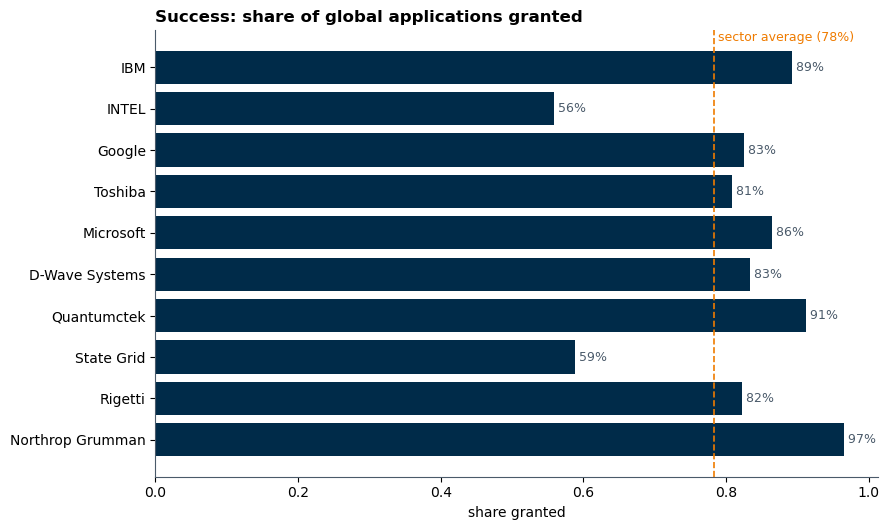

In [83]:
global_apps = national.merge(fam_firm, on="docdb_family_id")

success_global = global_apps.groupby("firm").granted.apply(lambda s: (s == "Y").mean()).reindex(TOP).rename("success_global")
sector_rate_global = (national.granted == "Y").mean()

firm_bars(
    success_global, 
    "Success: share of global applications granted", 
    "share granted", 
    fmt="{:.0%}",
    ref=sector_rate_global, 
    ref_label=f"sector average ({sector_rate_global:.0%})"
)

### 6.2 Refinement: success across offices, invention by invention

Offices apply different **patentability rules and standards**: the same invention can be granted in one country and refused in another. An invention granted at the EPO, in the USA, in China and in Japan has passed four different examinations: a strong signal. So we change the unit, from applications to **inventions**:

1. for each family, the share of its national applications that are granted
2. for each firm, the average over its families

As established in section 6.1, two kinds of family members  (**`WO`** and **Applications of kind `T`**) are **not** independent national examinations, so we exclude them.

To understand how grant standards differ across patent offices, we examine the grant rate by office for our sector's families:

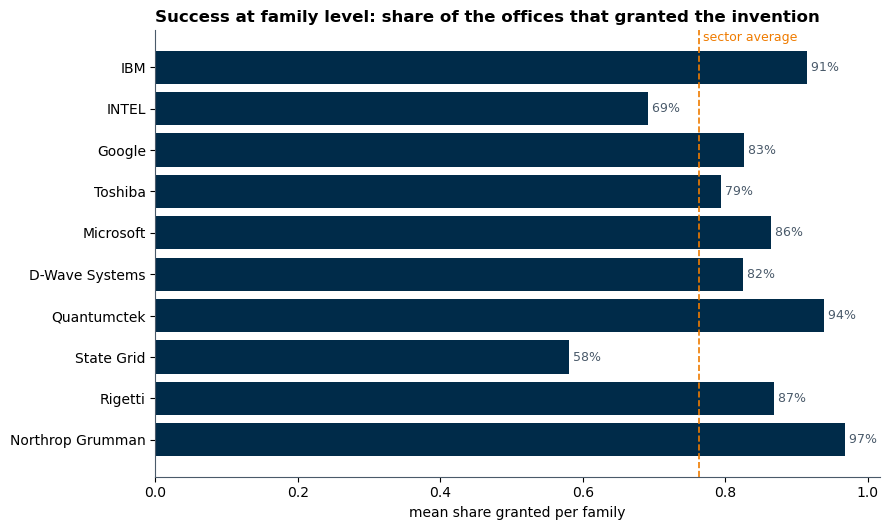

,6.1 global apps,6.2 family-level
firm,,
IBM,0.89,0.91
INTEL,0.56,0.69
Google,0.83,0.83
Toshiba,0.81,0.79
Microsoft,0.86,0.86
D-Wave Systems,0.83,0.82
Quantumctek,0.91,0.94
State Grid,0.59,0.58
Rigetti,0.82,0.87


In [84]:
families["family_success"] = families.docdb_family_id.map(
    national.groupby("docdb_family_id").granted.apply(lambda s: (s == "Y").mean())
)
family_success = per_firm("family_success")

# Plot family-level success across offices (Refinement)
firm_bars(
    family_success, 
    "Success at family level: share of the offices that granted the invention",
    "mean share granted per family", 
    fmt="{:.0%}", 
    ref=families.family_success.mean(), 
    ref_label="sector average"
)

pd.concat([success_global, family_success], axis=1) \
  .rename(columns={"success_global": "6.1 global apps", "family_success": "6.2 family-level"}) \
  .rename(index=SHORT) \
  .round(2)

**Reading the two columns together**

- **High in both**: The firm's innovations achieve are accepted both at the individual application level and across its patent families.
- **High in 6.1, Low in 6.2**: The firm shows a high application grant rate, but a lower average success rate when evaluated invention-by-invention (family level). 
- **Low in 6.1, High in 6.2**: The firm has a high average success rate per family, but a lower aggregate application success rate. 

### 6.3 Refinement: Grant Lag and Examination

The duration of the examination process measures the time elapsed from the initial filing date to the final grant of the patent. 
A hard-fought examination means the claims were rigorously tested against the prior art; a long lag also signals complex and uncertain technologies. Conversely, straightforward or incremental innovations may pass through the office much faster. The length of time an examiner spends evaluating an application serves as an interesting proxy for firm success:

$$\text{Grant Lag}_p = \text{Grant Date}_p - \text{Filing Date}_p$$

We compute the average grant lag across a firm’s granted patents to evaluate the complexity associated with its portfolio

* **Watch out:** Applicants can sometimes slow down the examination on purpose to keep their claims open while the market evolves.

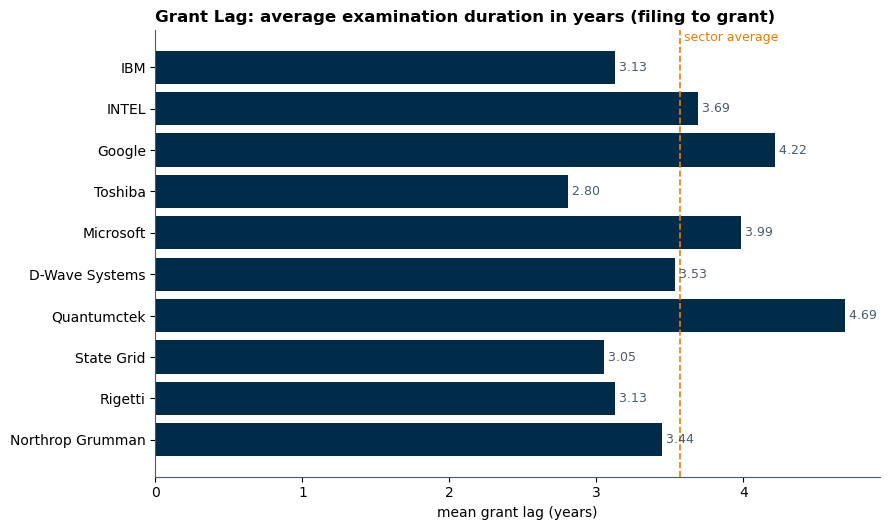

In [85]:
q_lag = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_filing_date,
        TLS211_PAT_PUBLN.publn_date,
        TLS201_APPLN.granted
    )
    .join(TLS211_PAT_PUBLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.granted == "Y")
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    .filter(TLS211_PAT_PUBLN.publn_first_grant == "Y")
)
lag_df = patstat.df(q_lag).drop_duplicates("appln_id")

lag_df["appln_filing_date"] = pd.to_datetime(lag_df["appln_filing_date"], errors="coerce")
lag_df["publn_date"] = pd.to_datetime(lag_df["publn_date"], errors="coerce")
lag_df["grant_lag_years"] = (lag_df["publn_date"] - lag_df["appln_filing_date"]).dt.days / 365.25

valid_lag = lag_df[(lag_df["grant_lag_years"] >= 0) & (lag_df["grant_lag_years"] <= 20)]

family_lag = valid_lag.groupby("docdb_family_id")["grant_lag_years"].mean()
families["family_lag"] = families.docdb_family_id.map(family_lag)

lag_firm = per_firm("family_lag").rename("grant_lag")

firm_bars(
    lag_firm, 
    "Grant Lag: average examination duration in years (filing to grant)", 
    "mean grant lag (years)", 
    ref=lag_firm.mean(), 
    ref_label="sector average"
)

### 6.4 Refinement: Number of Claims (Legal Scope)

The **number of claims** in a patent sets its legal boundary of protection. More claims generally mean a broader legal scope, offering multiple fallback positions and more ways to block imitators in the market. 

While applicants often try to balance breadth with clarity, a rich claim structure signals a well-protected invention and a strong strategic effort to secure commercial exclusivity across various facets of the technology.
* **Watch out:** Some applicants inflate claims for strategic reasons.

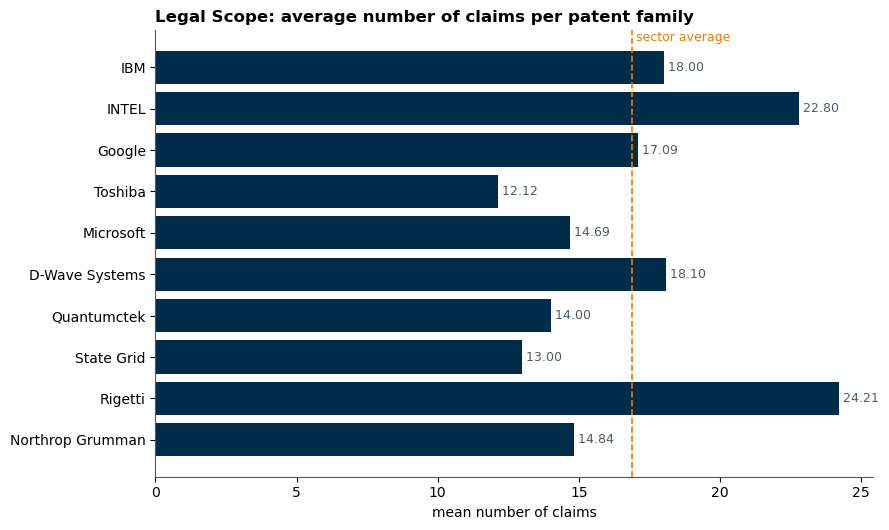

,6.1 global apps,6.2 family-level,6.3 grant lag (yrs),6.4 claims scope
firm,,,,
IBM,0.89,0.91,3.13,18.00
INTEL,0.56,0.69,3.69,22.80
Google,0.83,0.83,4.22,17.09
Toshiba,0.81,0.79,2.80,12.12
Microsoft,0.86,0.86,3.99,14.69
D-Wave Systems,0.83,0.82,3.53,18.10
Quantumctek,0.91,0.94,4.69,14.00
State Grid,0.59,0.58,3.05,13.00
Rigetti,0.82,0.87,3.13,24.21


In [86]:
q_claims = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS211_PAT_PUBLN.publn_claims
    )
    .join(TLS211_PAT_PUBLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)
claims_df = patstat.df(q_claims).drop_duplicates("appln_id")

claims_df["publn_claims"] = pd.to_numeric(claims_df["publn_claims"], errors="coerce").fillna(0)

family_claims = claims_df[claims_df["publn_claims"] > 0].groupby("docdb_family_id")["publn_claims"].mean()
families["family_claims"] = families.docdb_family_id.map(family_claims)

claims_firm = per_firm("family_claims").rename("number_of_claims")

firm_bars(
    claims_firm, 
    "Legal Scope: average number of claims per patent family", 
    "mean number of claims", 
    ref=claims_firm.mean(), 
    ref_label="sector average"
)

pd.concat([success_global, family_success, lag_firm, claims_firm], axis=1) \
  .rename(columns={
      "success_global": "6.1 global apps", 
      "family_success": "6.2 family-level",
      "grant_lag": "6.3 grant lag (yrs)",
      "number_of_claims": "6.4 claims scope"
  }) \
  .rename(index=SHORT) \
  .round(2)